<a href="https://colab.research.google.com/github/EMADUDDINAsdaq/Heart-Disease-Prediction/blob/main/notebooks/Word_LSTM_Language_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## CSC8637 Deep Learning Coursework – Task 2: Word-Level LSTM Language Model for “Poirot Investigates”

In [ ]:
import os
import re
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau
#set random state for reproducability
tf.random.set_seed(42)
np.random.seed(42)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

file_path = "/content/drive/MyDrive/deep_learning/COURSEWORK/61262.txt"

with open(file_path, "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Total characters:", len(raw_text))
print("\nPreview:\n")
print(raw_text[:1000])

Total characters: 296991

Preview:

*** START OF THE PROJECT GUTENBERG EBOOK 61262 ***

  POIROT INVESTIGATES




  BY THE SAME AUTHOR

  THE MYSTERIOUS AFFAIR AT STYLES

  THE SECRET ADVERSARY

  THE MURDER ON THE LINKS

  THE BODLEY HEAD




  POIROT INVESTIGATES

  BY AGATHA CHRISTIE




  LONDON

  JOHN LANE THE BODLEY HEAD LIMITED




  First published in Great Britain by
  John Lane Company, The Bodley Head Limited, 1924

  Copyright © 1924 Agatha Christie Limited




  CONTENTS


  I The Adventure of “The Western Star”

  II The Tragedy at Marsdon Manor

  III The Adventure of the Cheap Flat

  IV The Mystery of Hunter’s Lodge

  V The Million Dollar Bond Robbery

  VI The Adventure of the Egyptian Tomb

  VII Jewel Robbery at the _Grand Metropolitan_

  VIII The Kidnapped Prime Minister

  IX The Disappearance of Mr. Davenheim

  X The Adventure of the Italian Nobleman

  XI The Case of the Missing Will




  POIROT INVESTIGATES




  POIROT INVESTIGATES


  I


  The Adventure

In [ ]:

file_path = "/content/drive/MyDrive/deep_learning/COURSEWORK/61262.txt"

# Data Preprocessing
def load_and_clean_text(file_path):
    with open(file_path, "r", encoding="utf-8") as f:
        raw_text = f.read()

    #remove header and footer metadata
    start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"
    end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"

    if start_marker in raw_text and end_marker in raw_text:
      text = raw_text.split(start_marker)[1].split(end_marker)[0]
    else:
      text = raw_text

    #text start from narrative data to avoid learnig from contents section
    text = text[text.find("I was standing at the window"):]
    text = text[:text.find("THE END")]

    #normalising punctuation and spacing
    text = text.replace("_", "")
    text = text.replace("“", '"')
    text = text.replace("”", '"')
    text = text.replace("’", "'")

    #adding spacing around punctuations to set it as seperate tokens
    text = re.sub(r'([.,!?;:"()])', r' \1 ', text)
    #removing excess white spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

clean_text = load_and_clean_text(file_path)

In [ ]:
# FULL VOCABULARY

sequence_length = 100

vectorizer = layers.TextVectorization(
    max_tokens=5000, #cap vocabulary at 5000 that is around 95% of total vocabulary
    standardize=None,
    split="whitespace",
    output_mode="int"
)

vectorizer.adapt([clean_text])

vocab = vectorizer.get_vocabulary()
vocab_size = len(vocab)
print("Vocabulary size:", vocab_size)

# Verify special tokens (0 =padding , 1 = [UNK])
print("Index 0:", vocab[0])
print("Index 1:", vocab[1])

#conver text to token IDs
encoded = vectorizer([clean_text])[0].numpy()


Vocabulary size: 5000
Index 0: 
Index 1: [UNK]


In [ ]:
#Train validation and test split
split_index = int(len(encoded) * 0.8)

train_tokens = encoded[:split_index]
test_tokens = encoded[split_index:]

#fuction for sliding window sequence
#X = 100 previos words
#y = next word
def create_sequences(tokens, seq_length):
    X, y = [], []
    for i in range(len(tokens) - seq_length):
        X.append(tokens[i:i+seq_length])
        y.append(tokens[i+seq_length])
    return np.array(X), np.array(y)

# furter spliting train_tokens → 90% train, 10% validation

val_split = int(len(train_tokens) * 0.9)

final_train_tokens = train_tokens[:val_split]
val_tokens = train_tokens[val_split:]

# Create sequences
X_train, y_train = create_sequences(final_train_tokens, sequence_length)
X_val, y_val = create_sequences(val_tokens, sequence_length)
X_test, y_test = create_sequences(test_tokens, sequence_length)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

Train shape: (46753, 100)
Validation shape: (5106, 100)
Test shape: (12915, 100)


In [ ]:
# LSTM model architecture

embedding_dim = 256  #balances representation capacity and stability
lstm_units = 384     #tuned for better sequence modelling

model = tf.keras.Sequential([
    layers.Input(shape=(sequence_length,)),
    layers.Embedding(
    vocab_size,
    embedding_dim,
    embeddings_regularizer=tf.keras.regularizers.l2(1e-6)
    #l2 reqularisation to reduce overfitting
    ),
    #first layer
    layers.LSTM(lstm_units, return_sequences=True),
    #dropout increased to 0.4 to improve stability and generalisation
    layers.Dropout(0.4),
    #second layer
    layers.LSTM(lstm_units),
    layers.Dropout(0.4),
    # output layer
    layers.Dense(vocab_size, activation="softmax")
])

#adam optimizer
optimizer = tf.keras.optimizers.Adam(
    learning_rate=5e-4,
    clipnorm=1.0 #prevents exploding gradients
)

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=optimizer,
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 256)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100, 384)       │       984,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 384)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 384)            │     1,181,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5000)           │     1,925,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,370,760 (20.49 MB)

 Trainable params: 5,370,760 (20.49 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Training

#early stopping prevents overfitting
#stops traing if loss not improved
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

#reduce learnig rate if validation plateaus
lr_reduce = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-5
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=40,
    callbacks=[early_stop, lr_reduce]
)

Epoch 1/40
731/731 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.0658 - loss: 6.3583 - val_accuracy: 0.1056 - val_loss: 5.9261 - learning_rate: 5.0000e-04
Epoch 2/40
731/731 ━━━━━━━━━━━━━━━━━━━━ 31s 42ms/step - accuracy: 0.1327 - loss: 5.5426 - val_accuracy: 0.1314 - val_loss: 5.7844 - learning_rate: 5.0000e-04
Epoch 3/40
731/731 ━━━━━━━━━━━━━━━━━━━━ 33s 45ms/step - accuracy: 0.1521 - loss: 5.3348 - val_accuracy: 0.1481 - val_loss: 5.6393 - learning_rate: 5.0000e-04
Epoch 4/40
731/731 ━━━━━━━━━━━━━━━━━━━━ 34s 46ms/step - accuracy: 0.1657 - loss: 5.1285 - val_accuracy: 0.1535 - val_loss: 5.6159 - learning_rate: 5.0000e-04
Epoch 5/40
731/731 ━━━━━━━━━━━━━━━━━━━━ 33s 45ms/step - accuracy: 0.1715 - loss: 4.9963 - val_accuracy: 0.1573 - val_loss: 5.5849 - learning_rate: 5.0000e-04
Epoch 6/40
731/731 ━━━━━━━━━━━━━━━━━━━━ 33s 45ms/step - accuracy: 0.1790 - loss: 4.8970 - val_accuracy: 0.1631 - val_loss: 5.5622 - learning_rate: 5.0000e-04
Epoch 7/40
731/731 ━━━━━━━━━━━━━━━━━━━━ 33s 45ms/ste

In [ ]:
# Evaluvation

test_loss, test_acc = model.evaluate(X_test, y_test)

#perlexity = exp(loss) -- it measures next word prediction uncertainty
perplexity = np.exp(test_loss)

print("Test Accuracy:", test_acc)
print("Test Perplexity:", perplexity)

404/404 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.1728 - loss: 5.6534
Test Accuracy: 0.16453735530376434
Test Perplexity: 303.170510231361


In [ ]:
#save model for reproducability
save_path = "/content/drive/MyDrive/deep_learning/COURSEWORK/wordLM"
os.makedirs(save_path, exist_ok=True)

model.save(os.path.join(save_path, "wordLM.keras"))

print("Model saved successfully.")

# Save vocabulary
vocab_path = os.path.join(save_path, "vocab.npy")
np.save(vocab_path, vocab)

print("Vocabulary saved successfully.")

Model saved successfully.
Vocabulary saved successfully.


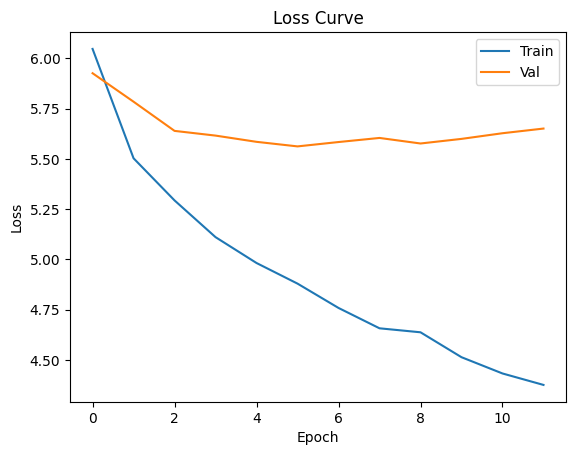

In [ ]:
#plot -- training  and validation loss
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.legend()
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [ ]:
# Text generation

index_to_word = dict(enumerate(vocab))
word_to_index = {word: idx for idx, word in index_to_word.items()}


def generate_text(seed_text, num_words=120, temperature=0.6):
    #0.6 temperature give more coherent and less random (control randomness)
    seed_tokens = seed_text.split()
    seed_indices = [word_to_index.get(w, 1) for w in seed_tokens]

    for _ in range(num_words):
        input_seq = seed_indices[-sequence_length:]
        if len(input_seq) < sequence_length:
            input_seq = [0] * (sequence_length - len(input_seq)) + input_seq

        preds = model.predict(np.array([input_seq]), verbose=0)[0]

        #temperature scaling
        preds = np.log(preds + 1e-8) / temperature
        preds = np.exp(preds)

        #removing padding and [unk] from generation
        preds[0] = 0
        preds[1] = 0


        preds /= np.sum(preds)

        next_index = np.random.choice(len(preds), p=preds)
        seed_indices.append(next_index)

    words = [index_to_word[i] for i in seed_indices]
    text = " ".join(words)

    #clean spacing and puncuation
    text = text.replace(" ,", ",")
    text = text.replace(" .", ".")
    text = text.replace(" !", "!")
    text = text.replace(" ?", "?")

    return text

In [ ]:
# N-GRAM memorisation check for overlap

def ngram_overlap(generated_text, original_text, n=4):
    def get_ngrams(text, n):
        tokens = text.split()
        return set(tuple(tokens[i:i+n]) for i in range(len(tokens)-n+1))

    gen_ngrams = get_ngrams(generated_text, n)
    orig_ngrams = get_ngrams(original_text, n)

    overlap = gen_ngrams.intersection(orig_ngrams)

    overlap_ratio = len(overlap) / max(len(gen_ngrams), 1)

    return overlap_ratio


In [ ]:
#ineractive generation
print("\nLanguage Model Ready.")
print("Type a seed phrase to generate text.")
print("Type 'q' to quit.\n")

while True:
    user_input = input("Enter starting text: ")

    if user_input.lower().strip() == "q":
        print("Exiting language model.")
        break

    if len(user_input.strip()) == 0:
        print("Please enter valid text.\n")
        continue

    generated = generate_text(user_input)

    print("\nGenerated Text:\n")
    print(generated)

    overlap = ngram_overlap(generated, clean_text, n=4)
    print("\n4-gram Overlap:", round(overlap, 4))

    if overlap > 0.3:
      print("High overlap — possible memorisation.")
    elif overlap > 0.1:
      print("Moderate overlap.")
    else:
      print("Low overlap — model is generating novel text.")

#example seed --
#Seed 1: Poirot looked at me gravely and said
#Seed 2: The door was locked from the inside
#Seed 3: Suddenly there was a knock at the door


Language Model Ready.
Type a seed phrase to generate text.
Type 'q' to quit.

Enter starting text: Poirot looked at me gravely and said

Generated Text:

Poirot looked at me gravely and said the farm later and the time. He had by the excited of the door. " " Poirot, and the door, I know. " I was been the little earlier over and the little offered. " " " Now, you of a old little amateur. He Yardly to no all. " " I have more the room, " I was obeyed. " " Yes, he know. " " Lord doctor, " " I went to my diamond. " I are would on the hands. " " And the Prime gesture. " The friend. " " Do Poirot, as Poirot, but you

4-gram Overlap: 0.0288
Low overlap — model is generating novel text.
Enter starting text: The door was locked from the inside

Generated Text:

The door was locked from the inside, you was the room. I shook the morning. " " I started, I must have talking about the small where the man, and the head at the door, who was be just the letters. " " You was here. " " But it. " " What, 

###Output from LLM(ChatGPT)
For starting seed (input) : "Poirot looked at me gravely and said"

", with that peculiar deliberation which always heralded some disquieting revelation. “My friend,” he murmured, adjusting the crease of his immaculate cuff, “you observe—but you do not perceive. That is the tragedy of the honest mind.”

I protested that I had perceived a great deal, but he silenced me with a gentle uplift of his hand.

“The facts, they arrange themselves with admirable symmetry. It is the human heart that introduces disorder. Consider the teacup—untouched. The window—latched from within. And yet—” He inclined his head. “There has been design. A design most subtle.”

A chill crept over me. “You suspect murder?”

Poirot sighed softly. “I suspect intelligence, Hastings. And that, perhaps, is far more dangerous.”

### Introduction
This project evaluates style-constrained text generation using a word-level LSTM model trained on a single Agatha Christie novel. Word-level modelling was required and selected to preserve lexical style and dialogue structure, despite increased sparsity relative to character-level approaches. The objective was to assess the model's ability to generate stylistically similar detective fiction from a given seed phrase while avoiding memorisation. Performance was evaluated using accuracy, perplexity, and 4-gram overlap, and the generated output was compared with a transformer-based large language model to highlight architectural differences.

### Data Preprocessing

Project Gutenberg metadata and non-narrative sections were removed to ensure the model learned only from the author's prose. The text was cleaned through punctuation spacing and normalisation, then tokenised using Keras TextVectorization, enabling distributed word representations [2]. Vocabulary analysis showed that 95% of usage was covered by the top 5000 words (from ~7000 total), so the vocabulary was capped at 5000 to reduce sparsity and computational complexity while maintaining stylistic richness. A sequence length of 100 was selected to provide adequate contextual information. The dataset was split 80/20 for training and testing, with the training portion further divided 90/10 for validation.

### Model and Training

The architecture consisted of a 256-dimensional embedding layer followed by two stacked LSTM layers [1] to improve sequential modelling and contextual representation. Dropout was increased from 0.3 to 0.4 to enhance stability and reduce overfitting, and L2 regularisation was applied to the embedding layer. The model was trained using the Adam optimiser with early stopping and learning-rate reduction to stabilise convergence. Early stopping and dropout were explicitly used to improve generalisation. Validation loss plateaued after approximately ten epochs, indicating limited further gains from additional training.

### Evaluation and Comparison

Although overall accuracy remained modest, perplexity—a standard evaluation metric in language modelling [3]—improved significantly (from 500 to 300) after vocabulary capping and hyperparameter tuning, indicating improved next-word prediction stability. A low 4-gram overlap (~0.02) suggests that the model generates novel text rather than memorising passages. Qualitatively, the LSTM captures local stylistic features such as dialogue structure and detective vocabulary, but exhibits grammatical inconsistencies and weak long-range coherence. In contrast, transformer-based models rely on self-attention mechanisms to model global context more effectively [4], producing grammatically coherent and logically structured output. The LLM benefits from large-scale pretraining and attention-based contextual modelling, whereas the LSTM compresses context sequentially through hidden states. This comparison highlights the trade-off between model simplicity and expressive power, demonstrating both the capability and architectural limitations of word-level LSTMs in style-constrained generation.

### References

[1] S. Hochreiter and J. Schmidhuber, “Long short-term memory,” Neural Computation, vol. 9, no. 8, pp. 1735–1780, 1997.

[2] T. Mikolov, I. Sutskever, K. Chen, G. Corrado and J. Dean, “Distributed representations of words and phrases and their compositionality,” in Advances in Neural Information Processing Systems (NeurIPS), 2013.

[3] S. F. Chen and J. Goodman, “An empirical study of smoothing techniques for language modeling,” in Proc. ACL, 1996, pp. 310–318.

[4] A. Vaswani et al., “Attention Is All You Need,” in Advances in Neural Information Processing Systems (NeurIPS), 2017.